# 08 · Fine-tuning II: preferences (DPO) and RL with verifiable rewards (GRPO)

**DPO** (Direct Preference Optimization) — RLHF's optimum in closed form; no reward model, no PPO:
$$\mathcal{L}_{DPO} = -\log\sigma\!\Big(\beta\big[\log\tfrac{\pi(y_w|x)}{\pi_{ref}(y_w|x)} - \log\tfrac{\pi(y_l|x)}{\pi_{ref}(y_l|x)}\big]\Big)$$
Raise the chosen answer's log-prob and lower the rejected one's, relative to a frozen reference; β controls how far the policy may drift.

**GRPO** (Group Relative Policy Optimization) — the engine behind DeepSeek-R1 and today's reasoning models: sample `G` answers per prompt, score them with a *verifier* (plain code), use the **group-normalized reward as the advantage** (no critic), add a KL penalty to the reference.

**Plan:** start from a *partially* trained SFT model (so there is room to improve) → DPO and its failure mode → DPO + NLL → GRPO with a sparse vs a dense reward → compare everything on the same held-out prompts.

**Source:** `llmsuite/finetune.py` (`dpo_loss`, `train_dpo`, `grpo_loss`, `train_grpo`).

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llmsuite.model import ModelConfig, TransformerLM
from llmsuite.data import ChatFormat, make_reverse_task, synthetic_structured_corpus, train_val_split
from llmsuite.training import TrainConfig, train_lm

V = 512
fmt = ChatFormat.for_vocab(V)                      # the last 5 ids are reserved for the role tokens SYS, USER, ASSIST, END, PAD
print("role tokens:", fmt)

# Our stand-in for a pretrained base model. A short run on the synthetic corpus teaches it the tokens, but no task.
data = synthetic_structured_corpus(n_tokens=100_000, vocab=V - 5)
train_data, val_data = train_val_split(data)
seed_everything(0)
base = TransformerLM(ModelConfig(vocab_size=V, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, max_seq_len=128))
train_lm(base, train_data, val_data, TrainConfig(steps=200, batch_size=32, block_size=64, max_lr=3e-3, warmup=20, eval_every=200, log=False), device)
print(f"base model: {human(base.num_params())} params")

# The instruction task is to reverse the user's token sequence, which needs attention to copy and reorder.
# We use 8000 examples: with only ~1500 the model memorises them (train loss around 0.1) but generalises poorly.
sft_train = make_reverse_task(fmt, n=8000, seed=0)
sft_test = make_reverse_task(fmt, n=200, seed=99)
inp, lab = sft_train[0]
print("example input :", inp.tolist())
print("example labels:", lab.tolist(), "  <- -100 = no loss (prompt), loss only on the reply")

role tokens: ChatFormat(sys_id=507, user_id=508, assist_id=509, end_id=510, pad_id=511)


base model: 758.91K params
example input : [507, 10, 510, 508, 389, 216, 21, 133, 262, 510, 509, 262, 133, 21, 216, 389]
example labels: [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 262, 133, 21, 216, 389, 510]   <- -100 = no loss (prompt), loss only on the reply


In [3]:
from llmsuite.finetune import greedy_answer
from llmsuite.evaluation import exact_match_rate, perplexity_on_examples

def reverse_cases(n=150, seed=7):
    rng = random.Random(seed)
    cases = []
    for _ in range(n):
        u = [rng.randint(1, 400) for _ in range(rng.randint(2, 5))]
        cases.append((u, u[::-1]))
    return cases

CASES = reverse_cases()          # 150 held-out prompts, shared by every method so the numbers are comparable
RESULTS = {}                      # maps name to (exact match, reply perplexity); evaluate() fills it in

def evaluate(model, name):
    """exact match = the greedy answer is exactly the reversed sequence; reply perplexity on held-out examples."""
    em = exact_match_rate(lambda u: greedy_answer(model, fmt, [10], u, device=device), CASES)
    ppl = perplexity_on_examples(model, sft_test, fmt, device=device)
    RESULTS[name] = (em, ppl)
    print(f"{name:24s} exact match {100*em:5.1f}%   reply perplexity {ppl:8.2f}")
    return em, ppl

def plot_results(title):
    names = list(RESULTS); ems = [100 * RESULTS[n][0] for n in names]; ppls = [RESULTS[n][1] for n in names]
    fig, ax = plt.subplots(1, 2, figsize=(12, 0.45 * len(names) + 1.5))
    ax[0].barh(names, ems, color="tab:blue"); ax[0].set_xlabel("exact match % (higher is better)"); ax[0].set_xlim(0, 100)
    for i, v in enumerate(ems): ax[0].text(v + 1, i, f"{v:.1f}%", va="center")
    ax[1].barh(names, ppls, color="tab:orange"); ax[1].set_xscale("log"); ax[1].set_xlabel("reply perplexity (log, lower is better)")
    for a in ax: a.invert_yaxis(); a.grid(alpha=.3, axis="x")
    ax[1].set_yticklabels([]); fig.suptitle(title); plt.tight_layout(); plt.show()

In [4]:
from llmsuite.finetune import train_sft
sft_model = copy.deepcopy(base)
# We stop early on purpose (900 of the 1500 steps notebook 07 uses) so preference tuning and RL have room to help.
train_sft(sft_model, sft_train, fmt, steps=900, batch_size=32, lr=1e-3, device=device, log_every=0)
evaluate(base, "base (no SFT)")
evaluate(sft_model, "SFT (partial)")

base (no SFT)            exact match   0.0%   reply perplexity 406983.87


SFT (partial)            exact match  70.7%   reply perplexity     1.76


(0.7066666666666667, 1.760666874671407)

## 1. DPO

Preference pairs for the reverse task: *chosen* = correct reversal, *rejected* = correct except the last token (a subtle error a reward model would have to catch). The policy starts from SFT; the reference is a frozen copy of it.

Watch: the loss (starts at ln 2 ≈ 0.693 because policy = reference), the **preference accuracy** (how often the implicit reward prefers the chosen answer), and the **log-probabilities** of chosen and rejected answers.

In [5]:
from llmsuite.data import make_reverse_preferences
from llmsuite.finetune import train_dpo

pairs = make_reverse_preferences(fmt, n=3000, seed=1)
dpo_model, hist = train_dpo(sft_model, pairs, fmt, steps=300, batch_size=16, lr=5e-5, beta=0.1, device=device, log_every=100)
evaluate(dpo_model, "SFT + DPO")

dpo step    0  loss 0.693  acc 0.00  margin +0.00


dpo step  100  loss 0.617  acc 0.75  margin +0.17


dpo step  200  loss 0.545  acc 0.88  margin +0.39


dpo step  299  loss 0.557  acc 0.75  margin +0.39


SFT + DPO                exact match  46.7%   reply perplexity     3.66


(0.4666666666666667, 3.664655030540622)

### DPO's failure mode: likelihood displacement

Preference accuracy goes up, yet the reply perplexity gets much **worse**. DPO only optimizes the *margin* between chosen and rejected. Our pairs differ by a single token, so the cheapest way to grow the margin is to push **both** log-probabilities down — including the correct answer's. This is a documented effect at real scale too (Razin et al. 2024, *Unintentional Unalignment*; Pal et al. 2024, *Smaug / DPO-Positive*).

The standard fix: add the SFT loss on the chosen answer, $\mathcal{L} = \mathcal{L}_{DPO} + \lambda\,\text{NLL}(y_w)$ ("DPO + NLL", Pang et al. 2024; `trl.DPOConfig(rpo_alpha=1.0)`). Here: `train_dpo(..., nll_weight=1.0)`.

dpo step    0  loss 1.448  acc 0.00  margin +0.00


dpo step  100  loss 1.084  acc 0.69  margin +0.07


dpo step  200  loss 1.011  acc 0.88  margin +0.11


dpo step  299  loss 0.924  acc 0.75  margin +0.08


SFT + DPO + NLL          exact match  80.0%   reply perplexity     1.46


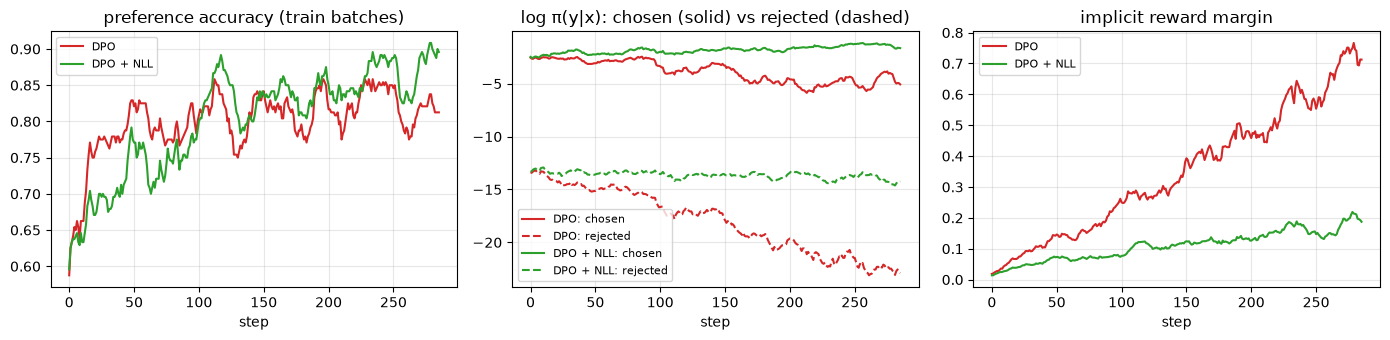

In [6]:
dpo_nll_model, hist_nll = train_dpo(sft_model, pairs, fmt, steps=300, batch_size=16, lr=5e-5, beta=0.1, device=device,
                                    log_every=100, nll_weight=1.0)
evaluate(dpo_nll_model, "SFT + DPO + NLL")

def smooth(v, k=15):
    v = np.asarray(v, dtype=float); return np.convolve(v, np.ones(k) / k, mode="valid")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for h, lab, c in [(hist, "DPO", "tab:red"), (hist_nll, "DPO + NLL", "tab:green")]:
    ax[0].plot(smooth([x["accuracy"] for x in h]), c=c, label=lab)
    ax[1].plot(smooth([x["chosen_logp"] for x in h]), c=c, label=f"{lab}: chosen")
    ax[1].plot(smooth([x["rejected_logp"] for x in h]), c=c, ls="--", label=f"{lab}: rejected")
    ax[2].plot(smooth([x["margin"] for x in h]), c=c, label=lab)
ax[0].set_title("preference accuracy (train batches)"); ax[1].set_title("log π(y|x): chosen (solid) vs rejected (dashed)")
ax[2].set_title("implicit reward margin")
for a in ax: a.set_xlabel("step"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Read the middle plot: compare the solid (chosen) lines. With plain DPO the chosen log-prob is dragged down together with the rejected one; with the NLL anchor the chosen answer keeps (or gains) likelihood while the rejected one is pushed away — the behaviour you actually want.

## 2. GRPO with a verifiable reward

The reward function is plain code — no labels, no reward model. At scale this is math answers checked by a parser or code checked by unit tests. The model learns from its own samples:

1. for each prompt sample `G = 8` answers,
2. score each with the reward function,
3. advantage $A_i = (r_i - \text{mean}(r)) / \text{std}(r)$ within the group,
4. raise the log-prob of above-average answers, lower below-average ones, with a KL penalty to the reference.

**Reward design matters.** A sparse reward (1 only when the whole answer is right) gives no signal when all 8 samples fail; a dense reward with partial credit (fraction of positions right, penalty for wrong length, bonus for ending with `END`) gives a gradient on every prompt — but it rewards *partially* correct answers, which is not the same as the metric we evaluate (exact match). We train both and compare on the held-out task metric.

*Note on the logged `pg` value:* advantages have mean 0 within each group and we take one gradient step per batch, so the policy-gradient **loss value** is ≈ 0 by construction — but its **gradient** is not. Judge progress by the reward curve and the held-out evaluation, not by `pg`.

grpo iter   0  mean reward 0.475  pg -0.000  kl 0.0000


grpo iter  50  mean reward 0.459  pg +0.000  kl 0.3507


grpo iter 100  mean reward 0.678  pg +0.000  kl 0.1276


grpo iter 149  mean reward 0.491  pg +0.000  kl 0.2984


SFT + GRPO exact         exact match  74.0%   reply perplexity     1.61


grpo iter   0  mean reward 0.890  pg -0.000  kl 0.0000


grpo iter  50  mean reward 0.913  pg +0.000  kl 0.2576


grpo iter 100  mean reward 1.009  pg +0.000  kl 0.2218


grpo iter 149  mean reward 0.892  pg +0.000  kl 0.5436


SFT + GRPO partial       exact match  72.7%   reply perplexity     1.59


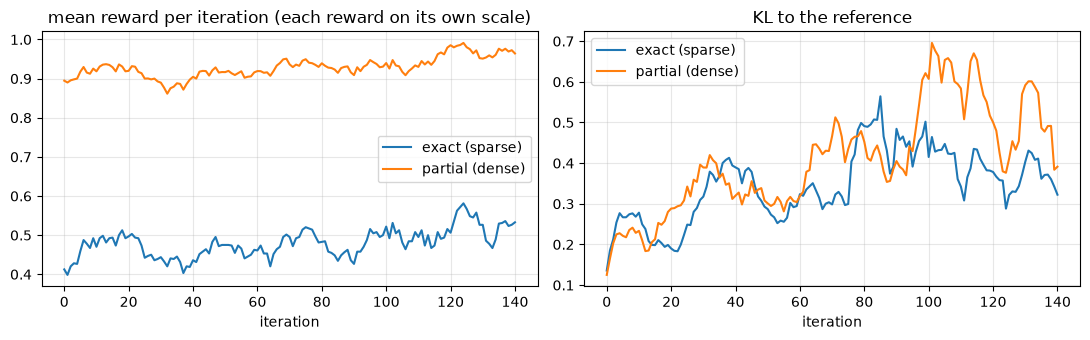

In [7]:
from llmsuite.finetune import train_grpo

def reward_exact(user, response):
    body = response[:-1] if response and response[-1] == fmt.end_id else response
    return (1.0 if body == user[::-1] else 0.0) + (0.1 if response and response[-1] == fmt.end_id else 0.0)

def reward_partial(user, response):
    body = response[:-1] if response and response[-1] == fmt.end_id else response
    target = user[::-1]
    correct = sum(a == b for a, b in zip(body, target)) / len(target)          # partial credit for every position that is right
    return correct - 0.1 * abs(len(body) - len(target)) + (0.2 if response and response[-1] == fmt.end_id else 0.0)

grpo_runs = {}
for name, rfn in [("exact (sparse)", reward_exact), ("partial (dense)", reward_partial)]:
    rng = random.Random(3)
    prompt_sampler = lambda: [rng.randint(1, 400) for _ in range(rng.randint(2, 5))]
    seed_everything(0)
    model_g, ghist = train_grpo(copy.deepcopy(sft_model), fmt, prompt_sampler, rfn, iters=150, prompts_per_iter=8, group_size=8,
                                lr=1e-4, beta=0.04, max_new=8, device=device, log_every=50)
    grpo_runs[name] = (model_g, ghist)
    evaluate(model_g, f"SFT + GRPO {name.split()[0]}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, (_, gh) in grpo_runs.items():
    ax[0].plot(smooth([h["reward"] for h in gh], 10), label=name); ax[1].plot(smooth([h["kl"] for h in gh], 10), label=name)
ax[0].set_title("mean reward per iteration (each reward on its own scale)"); ax[1].set_title("KL to the reference")
for a in ax: a.set_xlabel("iteration"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 3. Evaluation and comparison

Same held-out cases for every method, plus the training signals that matter for each:
- **DPO**: preference accuracy on *held-out* pairs, and that the chosen log-probs did not collapse (reply perplexity).
- **GRPO**: reward curve, KL to the reference (too high = reward hacking / forgetting), and *task accuracy on prompts never seen in training*.

DPO        held-out preference accuracy 0.75 | margin +0.69 | chosen log-prob -5.64
DPO + NLL  held-out preference accuracy 0.85 | margin +0.16 | chosen log-prob -1.65


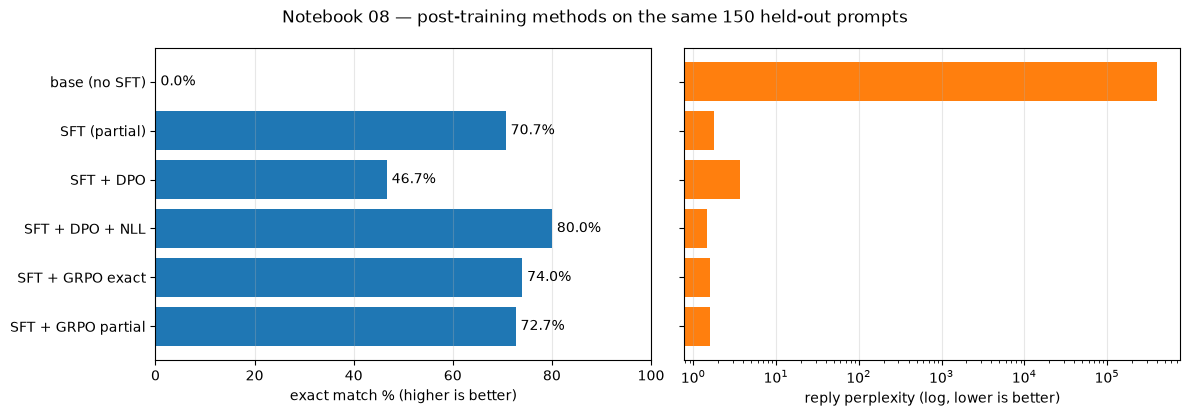

In [8]:
from llmsuite.finetune import dpo_loss
held_pairs = make_reverse_preferences(fmt, n=200, seed=42)
ci, cl = fmt.collate([c for c, _ in held_pairs]); ri, rl = fmt.collate([r for _, r in held_pairs])
for name, mdl in [("DPO", dpo_model), ("DPO + NLL", dpo_nll_model)]:
    with torch.no_grad():
        _, m = dpo_loss(mdl, sft_model, (ci.to(device), cl.to(device)), (ri.to(device), rl.to(device)), beta=0.1)
    print(f"{name:10s} held-out preference accuracy {m['accuracy']:.2f} | margin {m['margin']:+.2f} | chosen log-prob {m['chosen_logp']:.2f}")
plot_results("Notebook 08 — post-training methods on the same 150 held-out prompts")

**Reading the comparison.** DPO + NLL is the clear winner here. GRPO improves on SFT by a few points with either reward: the dense reward makes the *reward curve* look better, but that does not translate into more exact matches — optimizing a proxy is not the same as optimizing the metric you care about (Goodhart's law). On our tiny model, a few hundred RL updates move the needle less than preference pairs that directly contrast right and wrong answers; at scale, RL with verifiable rewards shines on reasoning tasks where the model can explore long solutions.

**Takeaways**
- DPO needs pairs; GRPO needs only a verifier. Both start from SFT and both are regularized toward it (β / KL).
- Always check that preference tuning did not hurt the likelihood of good answers — rising preference accuracy alone can hide a degraded model. DPO + NLL is a cheap, robust default.
- For RL, reward design is most of the work: dense, hard-to-game rewards learn faster; watch the KL and evaluate on held-out prompts to catch reward hacking.
- Real-scale practice: `trl.DPOTrainer(beta=0.1, learning_rate=5e-7, rpo_alpha=1.0)`; `trl.GRPOTrainer(num_generations=8–16, use_vllm=True)` with reward functions in Python. The bottleneck of GRPO is sampling, which is why vLLM runs the rollouts.
- Read: DPO (Rafailov 2023), DeepSeekMath (GRPO), DeepSeek-R1, DAPO / Dr. GRPO for the 2025 refinements.

**Next:** `09_quantization.ipynb`.